1. Chuẩn bị dữ liệu

In [1]:
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
PROJECT_ROOT = Path.cwd()

if not (PROJECT_ROOT / "official").exists():
    PROJECT_ROOT = PROJECT_ROOT.parent

DATASET_DIR = PROJECT_ROOT / "experiments" / "datasets"
DATASETS = {
    "ETTh1": DATASET_DIR / "ETT-small" / "ETTh1.csv",
    "ETTh2": DATASET_DIR / "ETT-small" / "ETTh2.csv",
    "ETTm1": DATASET_DIR / "ETT-small" / "ETTm1.csv",
    "ETTm2": DATASET_DIR / "ETT-small" / "ETTm2.csv",
    "Weather": DATASET_DIR / "weather.csv",
    "Electricity": DATASET_DIR / "electricity.csv",
}

print("Project root:", PROJECT_ROOT)
print("Dataset directory:", DATASET_DIR)

Project root: d:\TVCFORMER
Dataset directory: d:\TVCFORMER\experiments\datasets


2. Tổng quan

In [3]:
for name, path in DATASETS.items():
    print("=" * 60)
    print(f"Dataset: {name}")
    print(f"File exists: {path.exists()}")

    if not path.exists():
        continue

    df = pd.read_csv(path)

    print(f"Rows: {df.shape[0]:,}")
    print(f"Columns: {df.shape[1]}")
    print("Column names:", df.columns.tolist())
    print("\nData types:")
    print(df.dtypes)
    print("\nFirst 5 rows:")
    display(df.head())


Dataset: ETTh1
File exists: True
Rows: 17,420
Columns: 8
Column names: ['date', 'HUFL', 'HULL', 'MUFL', 'MULL', 'LUFL', 'LULL', 'OT']

Data types:
date     object
HUFL    float64
HULL    float64
MUFL    float64
MULL    float64
LUFL    float64
LULL    float64
OT      float64
dtype: object

First 5 rows:


,date,HUFL,HULL,MUFL,MULL,LUFL,LULL,OT
0,2016-07-01 00:00:00,5.827,2.009,1.599,0.462,4.203,1.340,30.531000
1,2016-07-01 01:00:00,5.693,2.076,1.492,0.426,4.142,1.371,27.787001
2,2016-07-01 02:00:00,5.157,1.741,1.279,0.355,3.777,1.218,27.787001
3,2016-07-01 03:00:00,5.090,1.942,1.279,0.391,3.807,1.279,25.044001
4,2016-07-01 04:00:00,5.358,1.942,1.492,0.462,3.868,1.279,21.948000


Dataset: ETTh2
File exists: True
Rows: 17,420
Columns: 8
Column names: ['date', 'HUFL', 'HULL', 'MUFL', 'MULL', 'LUFL', 'LULL', 'OT']

Data types:
date     object
HUFL    float64
HULL    float64
MUFL    float64
MULL    float64
LUFL    float64
LULL    float64
OT      float64
dtype: object

First 5 rows:


,date,HUFL,HULL,MUFL,MULL,LUFL,LULL,OT
0,2016-07-01 00:00:00,41.130001,12.481,36.535999,9.355,4.424,1.311,38.661999
1,2016-07-01 01:00:00,37.528000,10.136,33.936001,7.532,4.435,1.215,37.124001
2,2016-07-01 02:00:00,37.946999,11.309,35.330002,9.007,2.100,0.000,36.465000
3,2016-07-01 03:00:00,38.952000,11.895,35.543999,9.436,3.380,1.215,33.608501
4,2016-07-01 04:00:00,38.113998,11.476,35.410000,9.623,2.036,0.000,31.850500


Dataset: ETTm1
File exists: True
Rows: 69,680
Columns: 8
Column names: ['date', 'HUFL', 'HULL', 'MUFL', 'MULL', 'LUFL', 'LULL', 'OT']

Data types:
date     object
HUFL    float64
HULL    float64
MUFL    float64
MULL    float64
LUFL    float64
LULL    float64
OT      float64
dtype: object

First 5 rows:


,date,HUFL,HULL,MUFL,MULL,LUFL,LULL,OT
0,2016-07-01 00:00:00,5.827,2.009,1.599,0.462,4.203,1.340,30.531000
1,2016-07-01 00:15:00,5.760,2.076,1.492,0.426,4.264,1.401,30.459999
2,2016-07-01 00:30:00,5.760,1.942,1.492,0.391,4.234,1.310,30.038000
3,2016-07-01 00:45:00,5.760,1.942,1.492,0.426,4.234,1.310,27.013000
4,2016-07-01 01:00:00,5.693,2.076,1.492,0.426,4.142,1.371,27.787001


... (2 outputs left out)

Dataset: Weather
File exists: True
Rows: 52,696
Columns: 22
Column names: ['date', 'p (mbar)', 'T (degC)', 'Tpot (K)', 'Tdew (degC)', 'rh (%)', 'VPmax (mbar)', 'VPact (mbar)', 'VPdef (mbar)', 'sh (g/kg)', 'H2OC (mmol/mol)', 'rho (g/m**3)', 'wv (m/s)', 'max. wv (m/s)', 'wd (deg)', 'rain (mm)', 'raining (s)', 'SWDR (W/m�)', 'PAR (�mol/m�/s)', 'max. PAR (�mol/m�/s)', 'Tlog (degC)', 'OT']

Data types:
date                     object
p (mbar)                float64
T (degC)                float64
Tpot (K)                float64
Tdew (degC)             float64
rh (%)                  float64
VPmax (mbar)            float64
VPact (mbar)            float64
VPdef (mbar)            float64
sh (g/kg)               float64
H2OC (mmol/mol)         float64
rho (g/m**3)            float64
wv (m/s)                float64
max. wv (m/s)           float64
wd (deg)                float64
rain (mm)               float64
raining (s)             float64
SWDR (W/m�)             float64
PAR (�mol/m�/s)        

,date,p (mbar),T (degC),Tpot (K),Tdew (degC),rh (%),VPmax (mbar),VPact (mbar),VPdef (mbar),sh (g/kg),...,wv (m/s),max. wv (m/s),wd (deg),rain (mm),raining (s),SWDR (W/m�),PAR (�mol/m�/s),max. PAR (�mol/m�/s),Tlog (degC),OT
0,2020-01-01 00:10:00,1008.89,0.71,273.18,-1.33,86.1,6.43,5.54,0.89,3.42,...,1.02,1.60,224.3,0.0,0.0,0.0,0.0,0.0,11.45,428.1
1,2020-01-01 00:20:00,1008.76,0.75,273.22,-1.44,85.2,6.45,5.49,0.95,3.39,...,0.43,0.84,206.8,0.0,0.0,0.0,0.0,0.0,11.51,428.0
2,2020-01-01 00:30:00,1008.66,0.73,273.21,-1.48,85.1,6.44,5.48,0.96,3.39,...,0.61,1.48,197.1,0.0,0.0,0.0,0.0,0.0,11.60,427.6
3,2020-01-01 00:40:00,1008.64,0.37,272.86,-1.64,86.3,6.27,5.41,0.86,3.35,...,1.11,1.48,206.4,0.0,0.0,0.0,0.0,0.0,11.70,430.0
4,2020-01-01 00:50:00,1008.61,0.33,272.82,-1.50,87.4,6.26,5.47,0.79,3.38,...,0.49,1.40,209.6,0.0,0.0,0.0,0.0,0.0,11.81,432.2


Dataset: Electricity
File exists: True
Rows: 26,304
Columns: 322
Column names: ['date', '0', '1', '2', '3', '4', '5', '6', '7', '8', '9', '10', '11', '12', '13', '14', '15', '16', '17', '18', '19', '20', '21', '22', '23', '24', '25', '26', '27', '28', '29', '30', '31', '32', '33', '34', '35', '36', '37', '38', '39', '40', '41', '42', '43', '44', '45', '46', '47', '48', '49', '50', '51', '52', '53', '54', '55', '56', '57', '58', '59', '60', '61', '62', '63', '64', '65', '66', '67', '68', '69', '70', '71', '72', '73', '74', '75', '76', '77', '78', '79', '80', '81', '82', '83', '84', '85', '86', '87', '88', '89', '90', '91', '92', '93', '94', '95', '96', '97', '98', '99', '100', '101', '102', '103', '104', '105', '106', '107', '108', '109', '110', '111', '112', '113', '114', '115', '116', '117', '118', '119', '120', '121', '122', '123', '124', '125', '126', '127', '128', '129', '130', '131', '132', '133', '134', '135', '136', '137', '138', '139', '140', '141', '142', '143', '144', '145', 

,date,0,1,2,3,4,5,6,7,8,...,311,312,313,314,315,316,317,318,319,OT
0,2016-07-01 02:00:00,14.0,69.0,234.0,415.0,215.0,1056.0,29.0,840.0,226.0,...,676.0,372.0,80100.0,4719.0,5002.0,48.0,38.0,1558.0,182.0,2162.0
1,2016-07-01 03:00:00,18.0,92.0,312.0,556.0,292.0,1363.0,29.0,1102.0,271.0,...,805.0,452.0,95200.0,4643.0,6617.0,65.0,47.0,2177.0,253.0,2835.0
2,2016-07-01 04:00:00,21.0,96.0,312.0,560.0,272.0,1240.0,29.0,1025.0,270.0,...,817.0,430.0,96600.0,4285.0,6571.0,64.0,43.0,2193.0,218.0,2764.0
3,2016-07-01 05:00:00,20.0,92.0,312.0,443.0,213.0,845.0,24.0,833.0,179.0,...,801.0,291.0,94500.0,4222.0,6365.0,65.0,39.0,1315.0,195.0,2735.0
4,2016-07-01 06:00:00,22.0,91.0,312.0,346.0,190.0,647.0,16.0,733.0,186.0,...,807.0,279.0,91300.0,4116.0,6298.0,75.0,40.0,1378.0,191.0,2721.0


3. Missing values

In [4]:

for name, path in DATASETS.items():
    if not path.exists():
        continue

    df = pd.read_csv(path)
    print(f"\n{'=' * 60}\n{name}")
    print("Missing values:")
    display(df.isna().sum().to_frame("missing_count"))

    print("Descriptive statistics:")
    display(df.describe(include="all").T)



ETTh1
Missing values:


,missing_count
date,0
HUFL,0
HULL,0
MUFL,0
MULL,0
LUFL,0
LULL,0
OT,0


Descriptive statistics:


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
date,17420,17420,2016-07-01 00:00:00,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
HUFL,17420.0,NaN,NaN,NaN,7.375141,7.067744,-22.705999,5.827,8.774,11.788,23.643999
HULL,17420.0,NaN,NaN,NaN,2.242242,2.042342,-4.756,0.737,2.21,3.684,10.114
MUFL,17420.0,NaN,NaN,NaN,4.300239,6.826978,-25.087999,3.296,5.97,8.635,17.341
MULL,17420.0,NaN,NaN,NaN,0.881568,1.809293,-5.934,-0.284,0.959,2.203,7.747
LUFL,17420.0,NaN,NaN,NaN,3.066062,1.164506,-1.188,2.315,2.833,3.625,8.498
LULL,17420.0,NaN,NaN,NaN,0.856932,0.599552,-1.371,0.67,0.975,1.218,3.046
OT,17420.0,NaN,NaN,NaN,13.324672,8.566946,-4.08,6.964,11.396,18.079,46.007



ETTh2
Missing values:


,missing_count
date,0
HUFL,0
HULL,0
MUFL,0
MULL,0
LUFL,0
LULL,0
OT,0


... (14 outputs left out)


Electricity
Missing values:


,missing_count
date,0
0,0
1,0
2,0
3,0
...,...
316,0
317,0
318,0
319,0


Descriptive statistics:


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
date,26304,26304,2016-07-01 02:00:00,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
0,26304.0,NaN,NaN,NaN,23.263762,24.127164,0.0,9.0,11.0,24.0,140.0
1,26304.0,NaN,NaN,NaN,112.885569,25.553141,0.0,95.0,113.0,130.0,296.0
2,26304.0,NaN,NaN,NaN,16.821624,49.190377,0.0,8.0,8.0,10.0,601.0
3,26304.0,NaN,NaN,NaN,440.335196,152.60105,0.0,334.75,400.0,511.0,1170.0
...,...,...,...,...,...,...,...,...,...,...,...
316,26304.0,NaN,NaN,NaN,350.702137,241.241444,0.0,94.0,361.0,505.0,1330.0
317,26304.0,NaN,NaN,NaN,51.490344,37.228837,0.0,27.0,37.0,57.0,205.0
318,26304.0,NaN,NaN,NaN,2264.188641,545.279372,0.0,1999.0,2319.0,2607.0,4449.0
319,26304.0,NaN,NaN,NaN,507.008858,267.445473,0.0,233.0,504.0,704.0,1369.0


4. Kiểm tra trùng lặp

In [5]:
for name, path in DATASETS.items():
    if not path.exists():
        print(f"[NOT FOUND] {name}: {path}")
        continue

    df = pd.read_csv(path)
    print(f"\n{'=' * 60}\n{name}")
    if "date" not in df.columns:
        print("Không tìm thấy cột date.")
        continue

    dates = pd.to_datetime(df["date"], errors="coerce")
    duplicated_dates = dates.duplicated(keep=False)

    print(
        "Số dòng có timestamp bị trùng:",
        int(duplicated_dates.sum())
    )
    print(
        "Số timestamp trùng khác nhau:",
        int(dates[duplicated_dates].nunique())
    )

    if duplicated_dates.any():
        # Hiển thị một số bản ghi để kiểm tra nguyên nhân trùng thời gian
        display(
            df.loc[duplicated_dates]
            .assign(date=dates[duplicated_dates])
            .sort_values("date")
            .head(10)
        )


ETTh1
Số dòng có timestamp bị trùng: 0
Số timestamp trùng khác nhau: 0

ETTh2
Số dòng có timestamp bị trùng: 0
Số timestamp trùng khác nhau: 0

ETTm1
Số dòng có timestamp bị trùng: 0
Số timestamp trùng khác nhau: 0

ETTm2
Số dòng có timestamp bị trùng: 0
Số timestamp trùng khác nhau: 0

Weather
Số dòng có timestamp bị trùng: 2
Số timestamp trùng khác nhau: 1


,date,p (mbar),T (degC),Tpot (K),Tdew (degC),rh (%),VPmax (mbar),VPact (mbar),VPdef (mbar),sh (g/kg),...,wv (m/s),max. wv (m/s),wd (deg),rain (mm),raining (s),SWDR (W/m�),PAR (�mol/m�/s),max. PAR (�mol/m�/s),Tlog (degC),OT
19043,2020-05-12 06:00:00,991.53,-1.57,272.25,-2.09,96.2,5.44,5.24,0.21,3.29,...,1.04,1.68,215.4,0.0,0.0,84.91,176.64,199.61,10.19,445.9
19044,2020-05-12 06:00:00,991.53,-1.57,272.25,-2.09,96.2,5.44,5.24,0.21,3.29,...,1.04,1.68,215.4,0.0,0.0,84.91,176.64,199.61,10.19,445.9



Electricity
Số dòng có timestamp bị trùng: 0
Số timestamp trùng khác nhau: 0


5. Xử lý trùng lặp

In [6]:
# xl trùng lặp
for name, path in DATASETS.items():
    if not path.exists():
        print(f"[NOT FOUND] {name}: {path}")
        continue

    df = pd.read_csv(path)
    print(f"\n{'=' * 60}\n{name}")

    if "date" not in df.columns:
        print("Không tìm thấy cột date.")
        continue

    df["date"] = pd.to_datetime(df["date"], errors="coerce")

    # Đếm số dòng có timestamp trùng trước xử lý
    duplicated = df["date"].duplicated(keep=False)
    print("Số dòng trùng trước xử lý:", int(duplicated.sum()))

    # Ưu tiên giữ bản ghi có nhiều dữ liệu hợp lệ hơn
    df["_valid_count"] = df.notna().sum(axis=1)
    df = df.sort_values("_valid_count", ascending=False, kind="stable")
    df = df.drop_duplicates(subset=["date"], keep="first")

    # Xóa cột phụ và sắp xếp lại theo thời gian
    df = df.drop(columns=["_valid_count"])
    df = df.sort_values("date").reset_index(drop=True)

    print("Số dòng trùng sau xử lý:",
          int(df["date"].duplicated(keep=False).sum()))
    print("Số dòng còn lại:", len(df))



ETTh1
Số dòng trùng trước xử lý: 0
Số dòng trùng sau xử lý: 0
Số dòng còn lại: 17420

ETTh2
Số dòng trùng trước xử lý: 0
Số dòng trùng sau xử lý: 0
Số dòng còn lại: 17420

ETTm1
Số dòng trùng trước xử lý: 0
Số dòng trùng sau xử lý: 0
Số dòng còn lại: 69680

ETTm2
Số dòng trùng trước xử lý: 0
Số dòng trùng sau xử lý: 0
Số dòng còn lại: 69680

Weather
Số dòng trùng trước xử lý: 2
Số dòng trùng sau xử lý: 0
Số dòng còn lại: 52695

Electricity
Số dòng trùng trước xử lý: 0
Số dòng trùng sau xử lý: 0
Số dòng còn lại: 26304


6. Trực quan hóa dữ liệu chuỗi thời gian

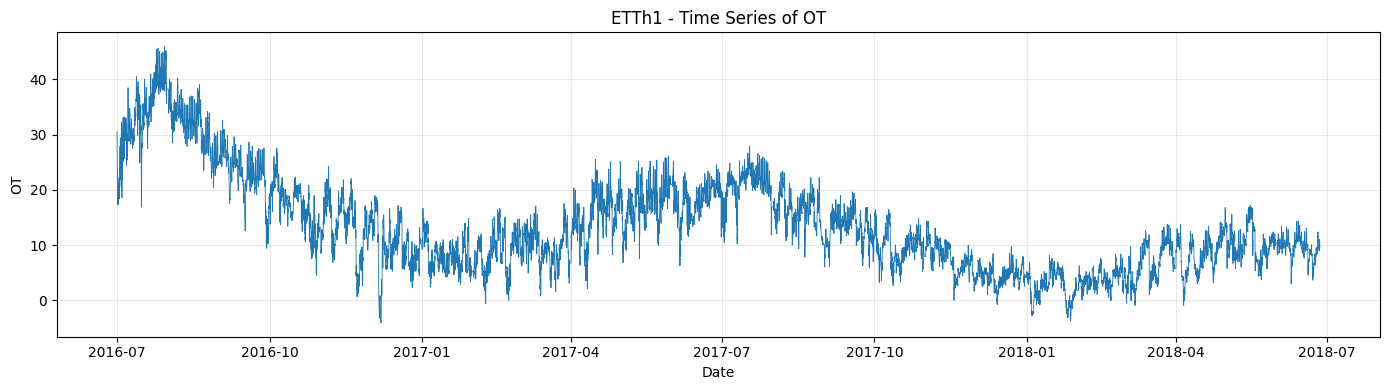

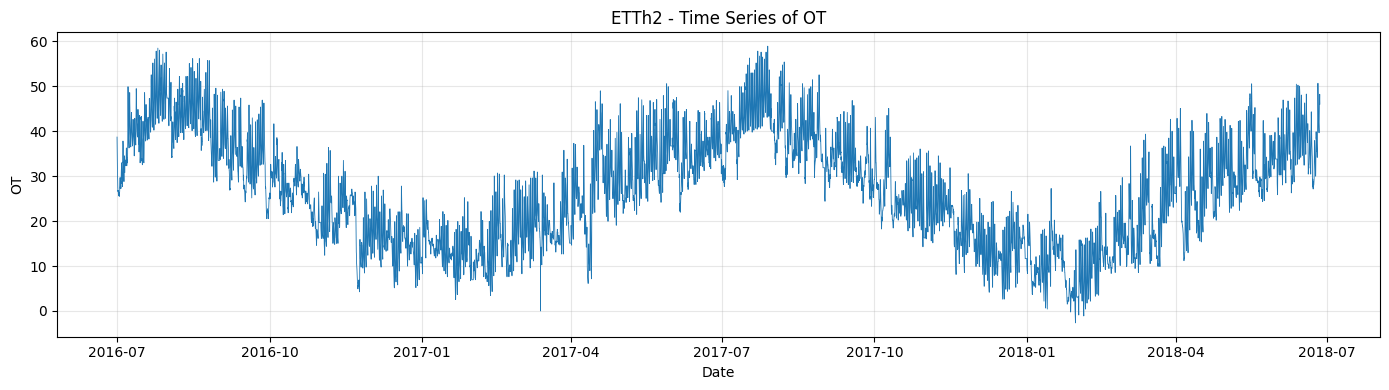

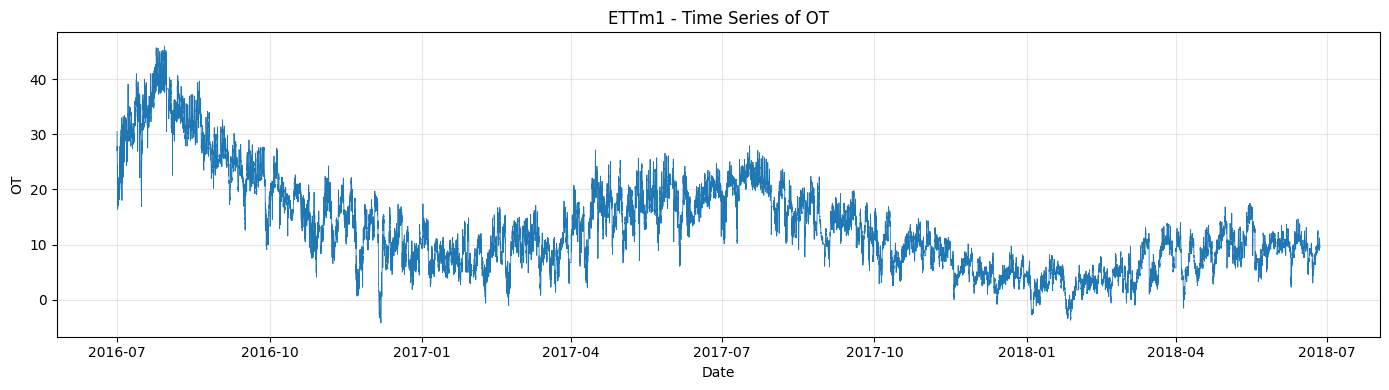

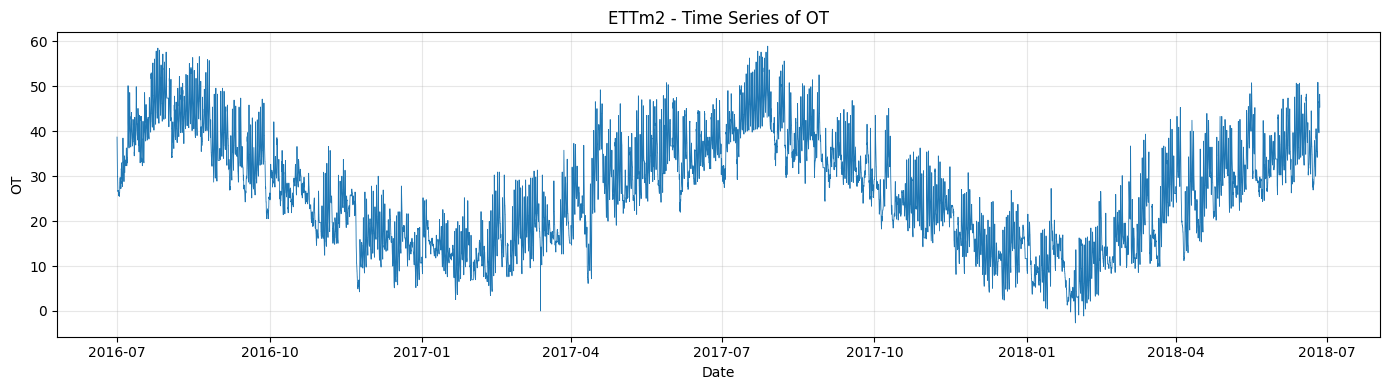

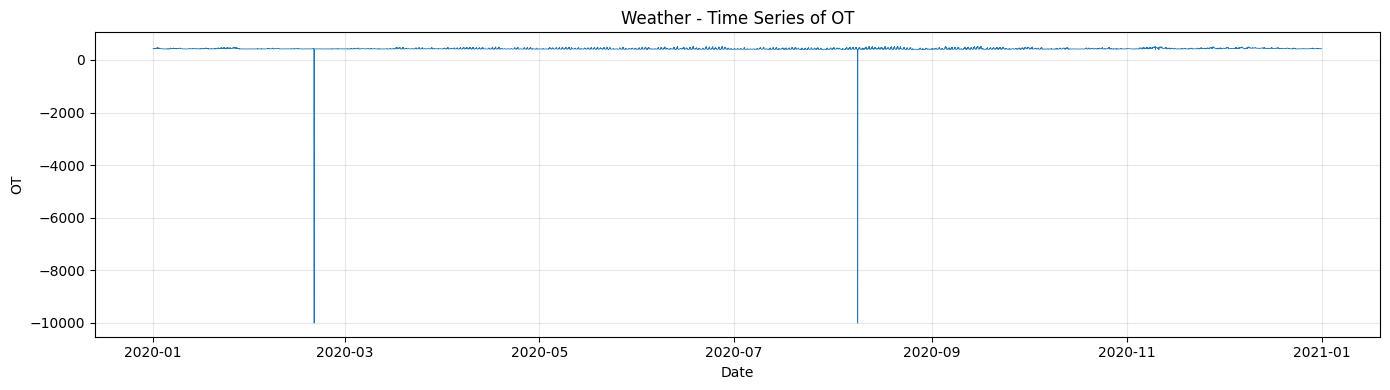

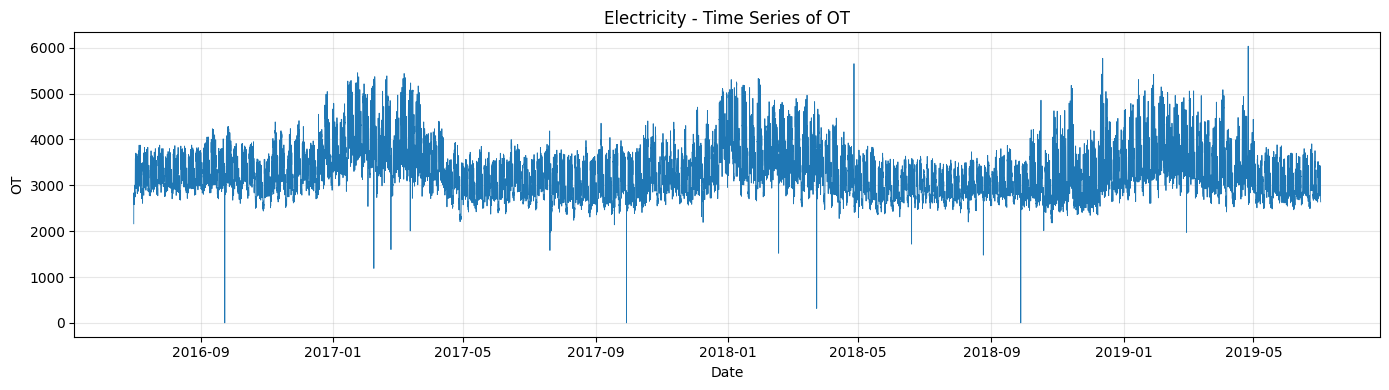

In [7]:
for name, path in DATASETS.items():
    if not path.exists():
        print(f"[NOT FOUND] {name}: {path}")
        continue

    df = pd.read_csv(path)

    if "date" not in df.columns:
        print(f"{name}: Không tìm thấy cột date.")
        continue

    df["date"] = pd.to_datetime(df["date"], errors="coerce")

    # Ưu tiên OT nếu có; nếu không, chọn biến số đầu tiên
    numeric_cols = df.select_dtypes(include="number").columns

    if len(numeric_cols) == 0:
        print(f"{name}: Không có cột số để trực quan hóa.")
        continue

    target = "OT" if "OT" in df.columns else numeric_cols[0]

    df = (
        df.dropna(subset=["date", target]) # loại bỏ các dòg bị thiếu tgian or gtri of biến
        .sort_values("date")
    )

    plt.figure(figsize=(14, 4))
    plt.plot(df["date"], df[target], linewidth=0.6)

    plt.title(f"{name} - Time Series of {target}")
    plt.xlabel("Date")
    plt.ylabel(target)
    plt.grid(alpha=0.3)
    plt.tight_layout()
    plt.show()

7. Histogram kết hợp KDE

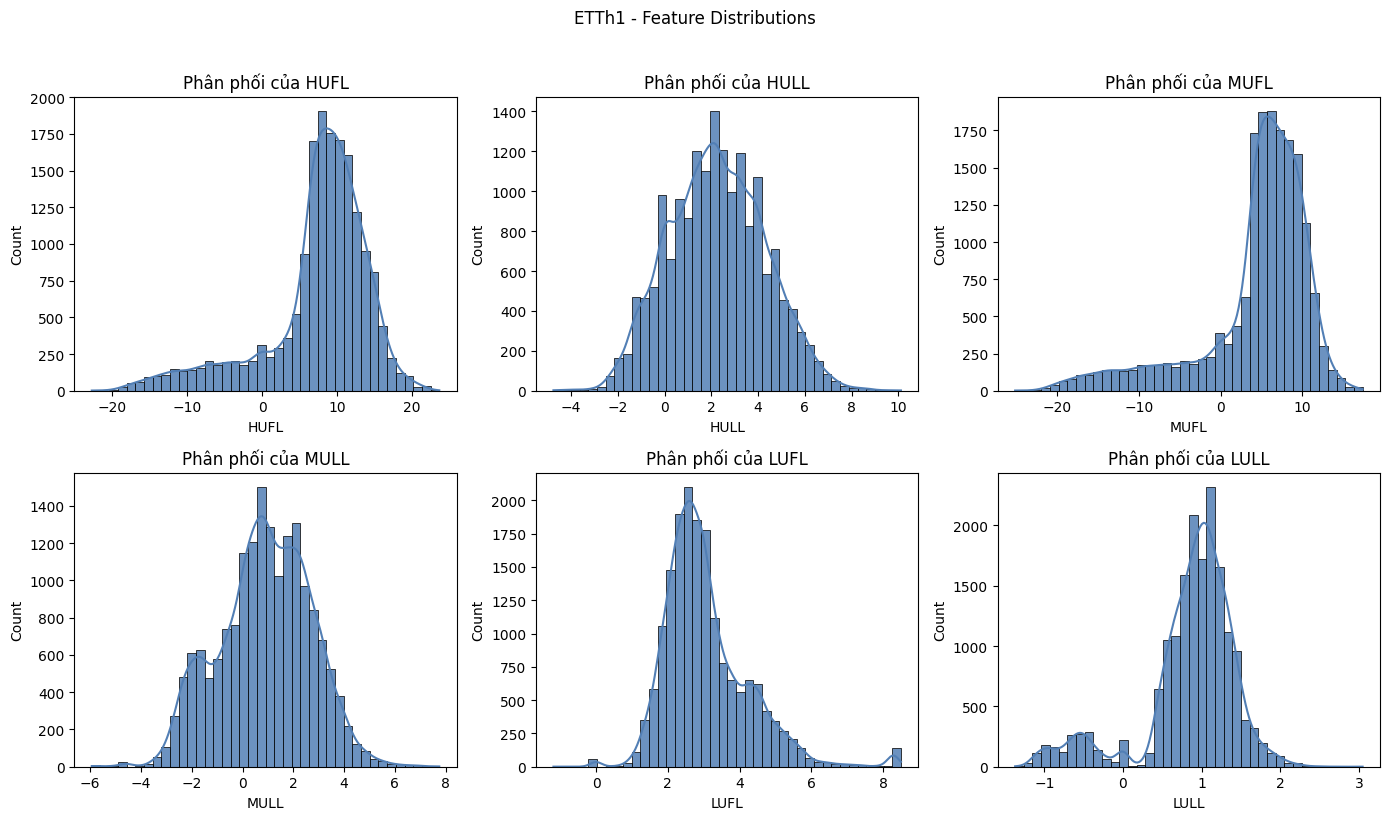

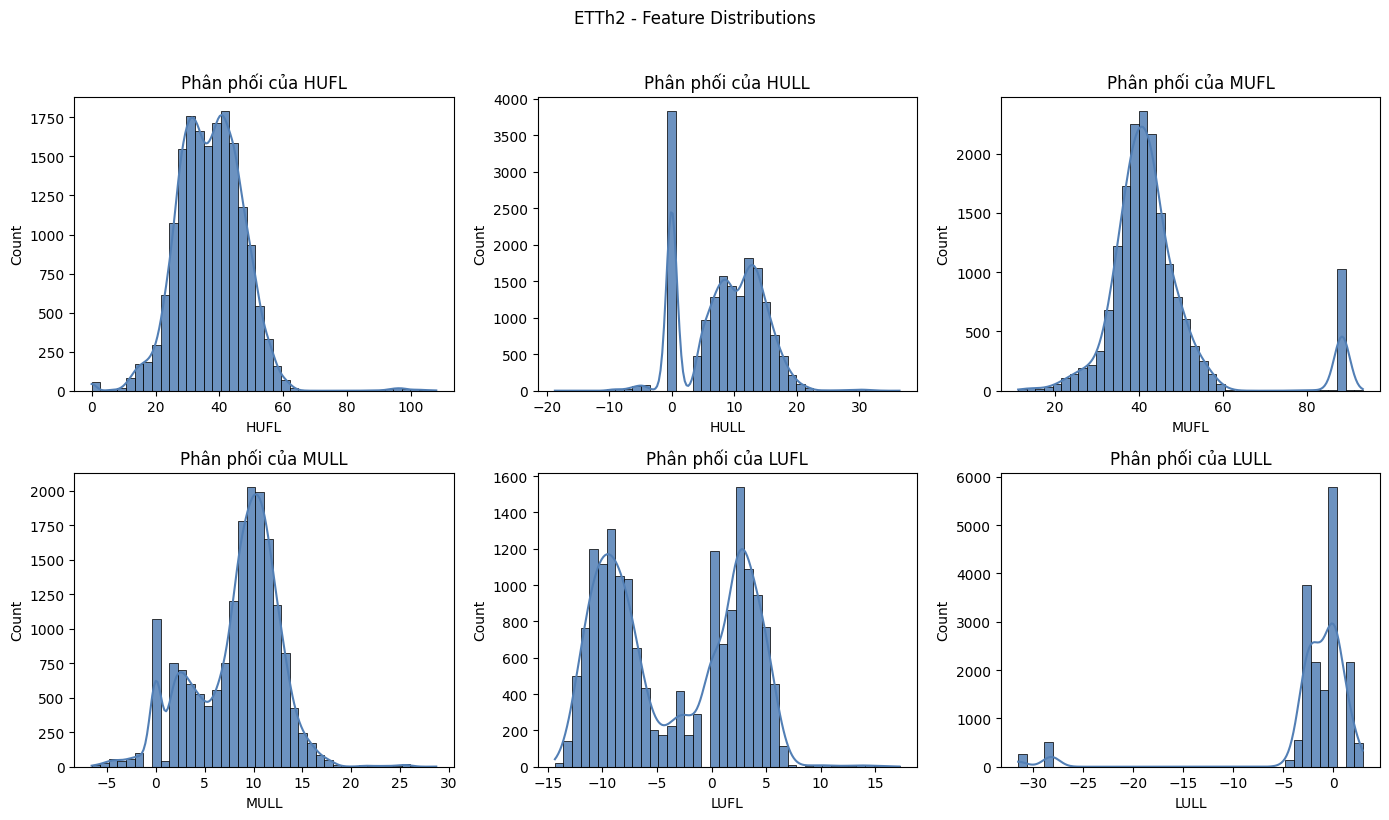

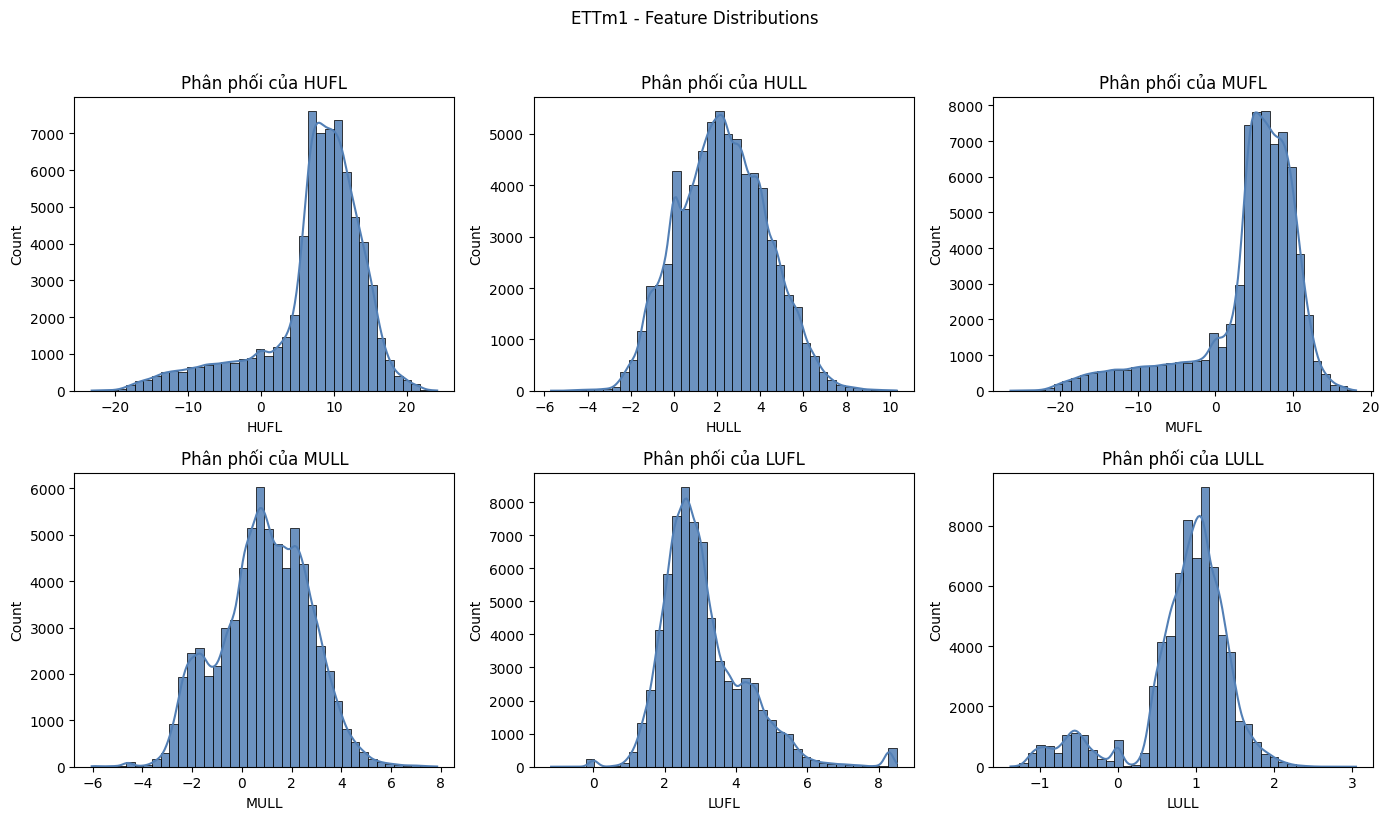

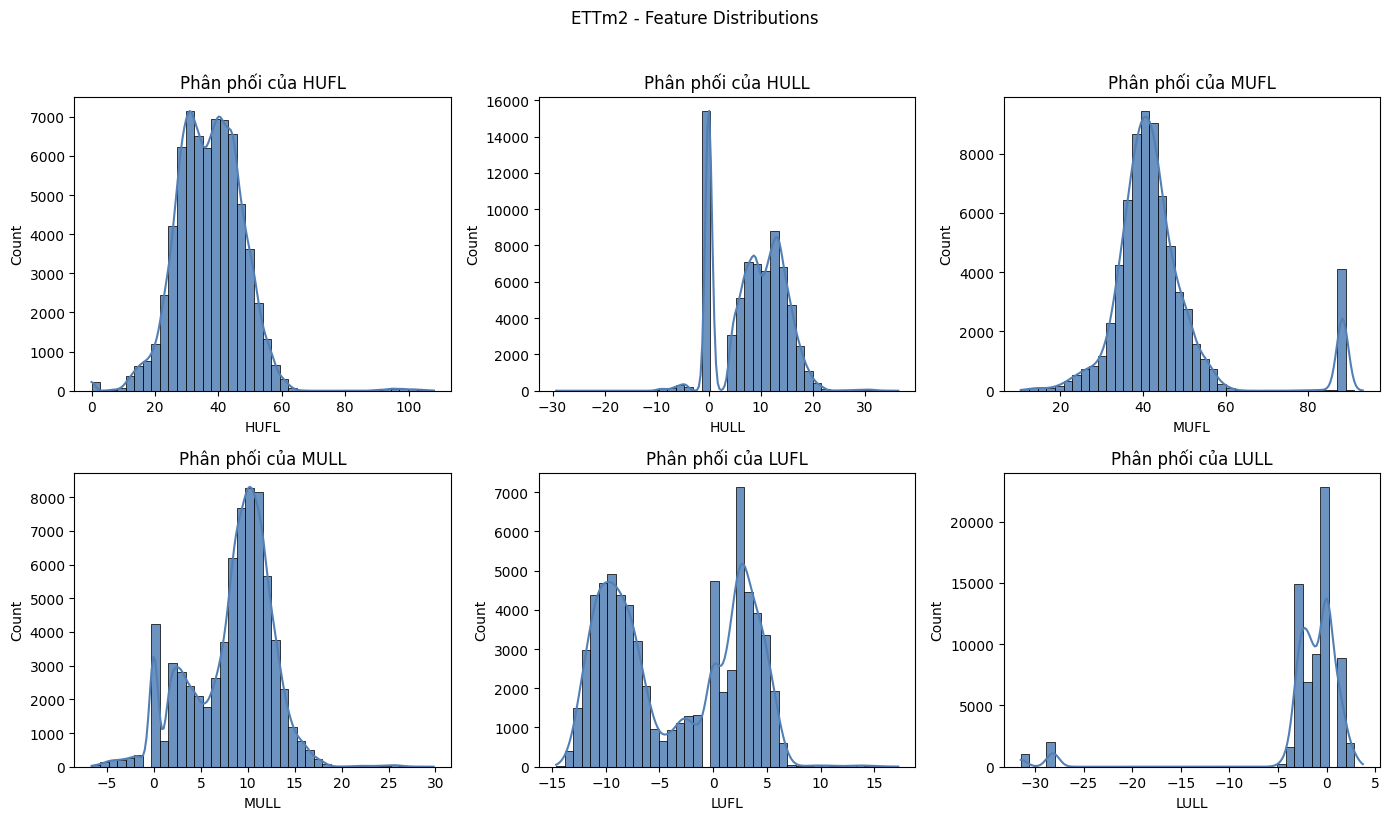

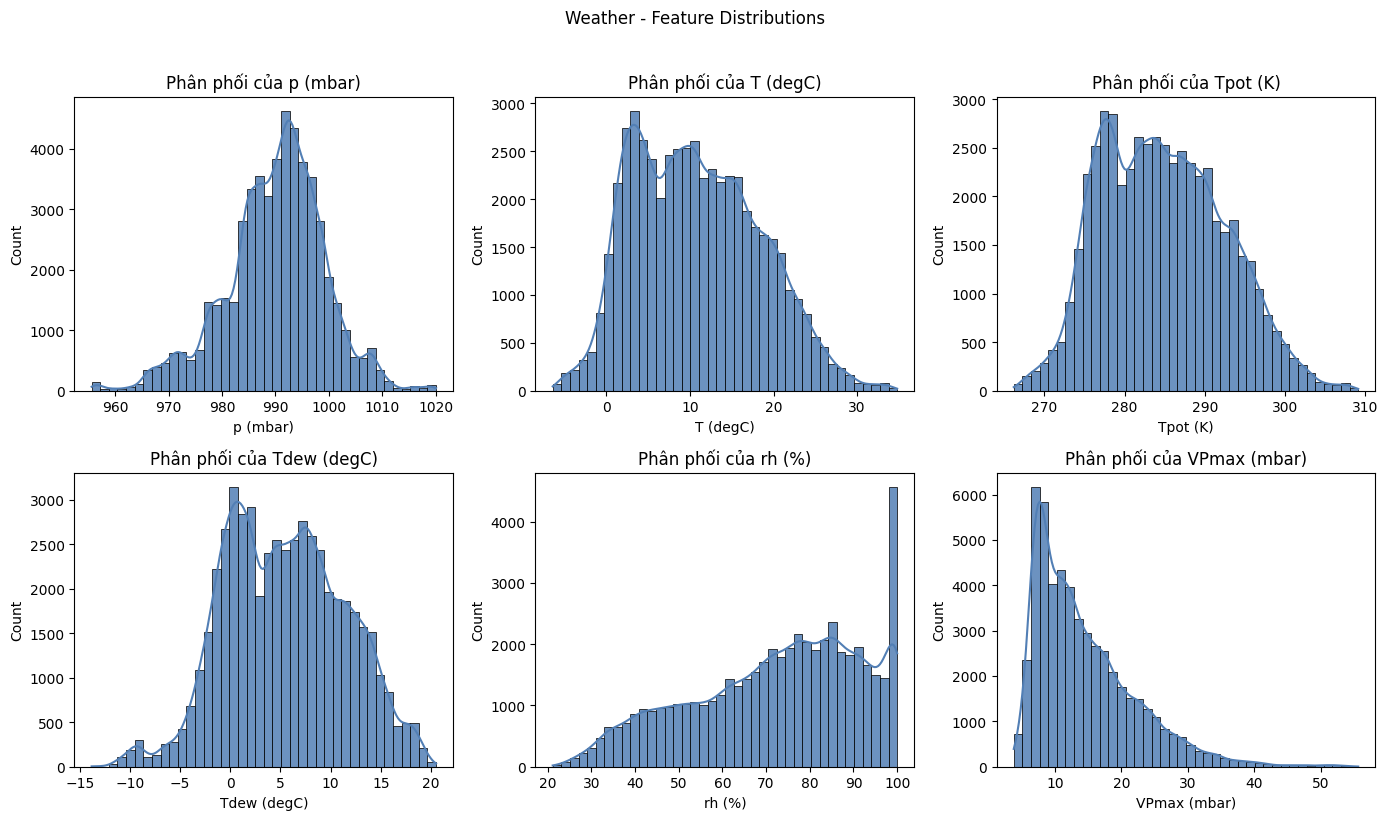

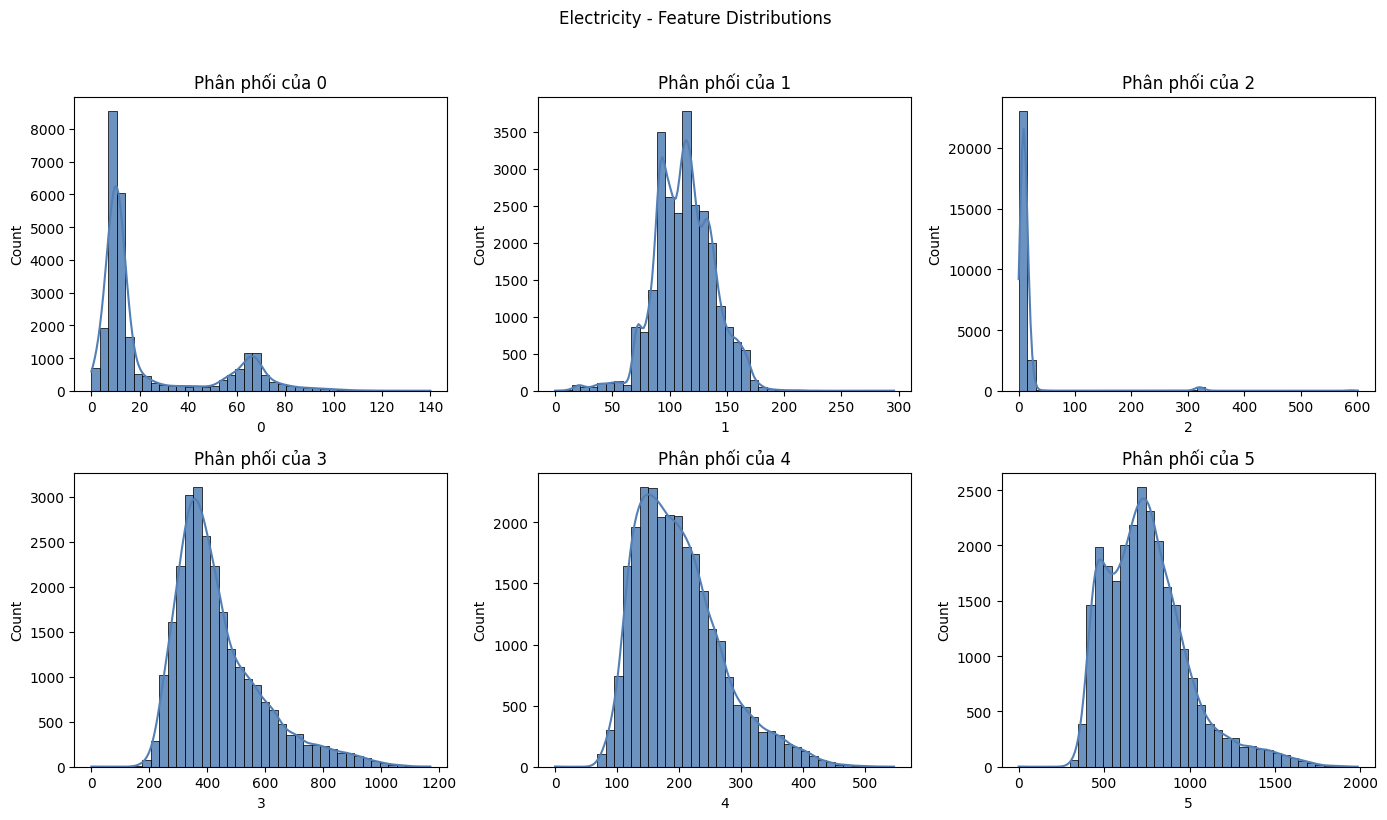

In [8]:

for name, path in DATASETS.items():
    if not path.exists():
        continue

    df = pd.read_csv(path)
    numeric_cols = df.select_dtypes(include="number").columns.tolist()

    if not numeric_cols:
        print(f"{name}: Không có cột số.")
        continue

    # Chọn tối đa 6 biến số để biểu đồ dễ đọc
    selected_cols = numeric_cols[:6]

    n_cols = 3
    n_rows = (len(selected_cols) + n_cols - 1) // n_cols

    fig, axes = plt.subplots(
        n_rows,
        n_cols,
        figsize=(14, 4 * n_rows)
    )

    axes = np.array(axes).flatten()

    # vẽ histogram vs khoagr 40 gtri
    for i, col in enumerate(selected_cols):
        sns.histplot(
            data=df,
            x=col,
            bins=40,
            kde=True,
            color="#527FB5",
            edgecolor="black",
            alpha=0.85,
            ax=axes[i]
        )
        axes[i].set_title(f"Phân phối của {col}")

    # Ẩn các ô biểu đồ không sử dụng
    for i in range(len(selected_cols), len(axes)):
        axes[i].set_visible(False)

    plt.suptitle(f"{name} - Feature Distributions", y=1.02)
    plt.tight_layout()
    plt.show()


8. Phân tích tương quan giữa các biến

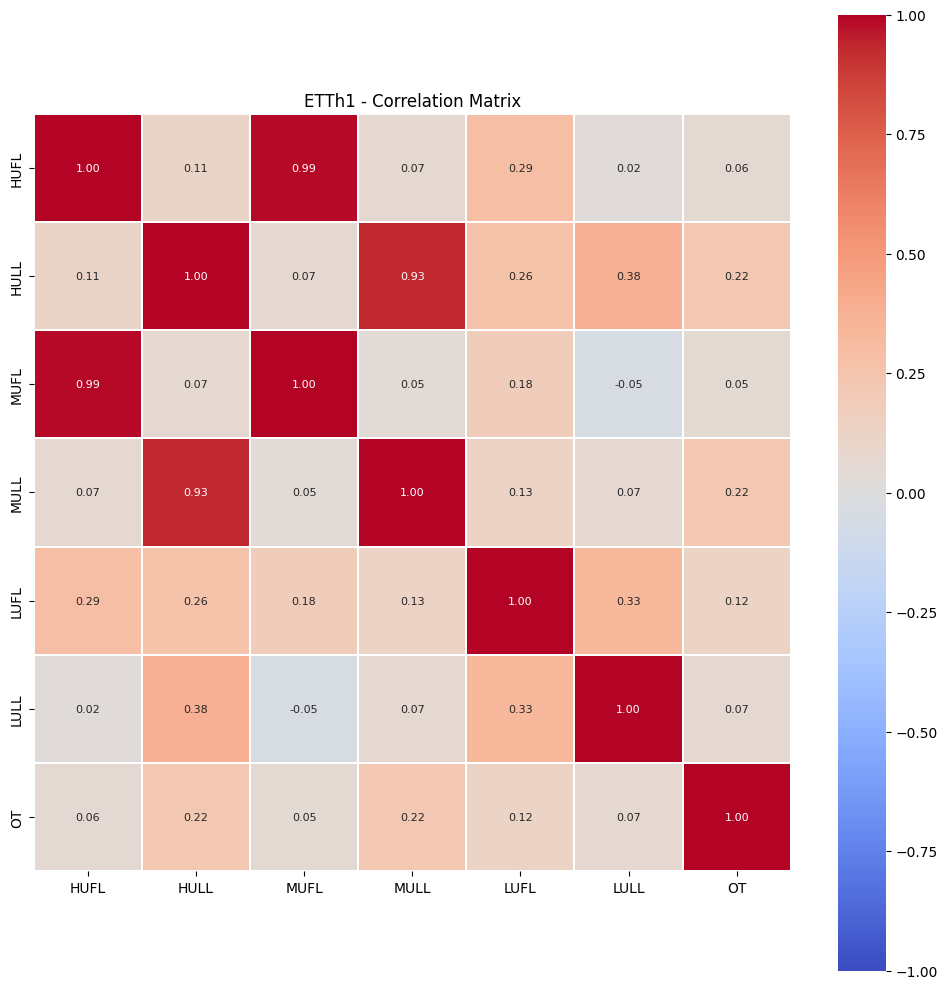

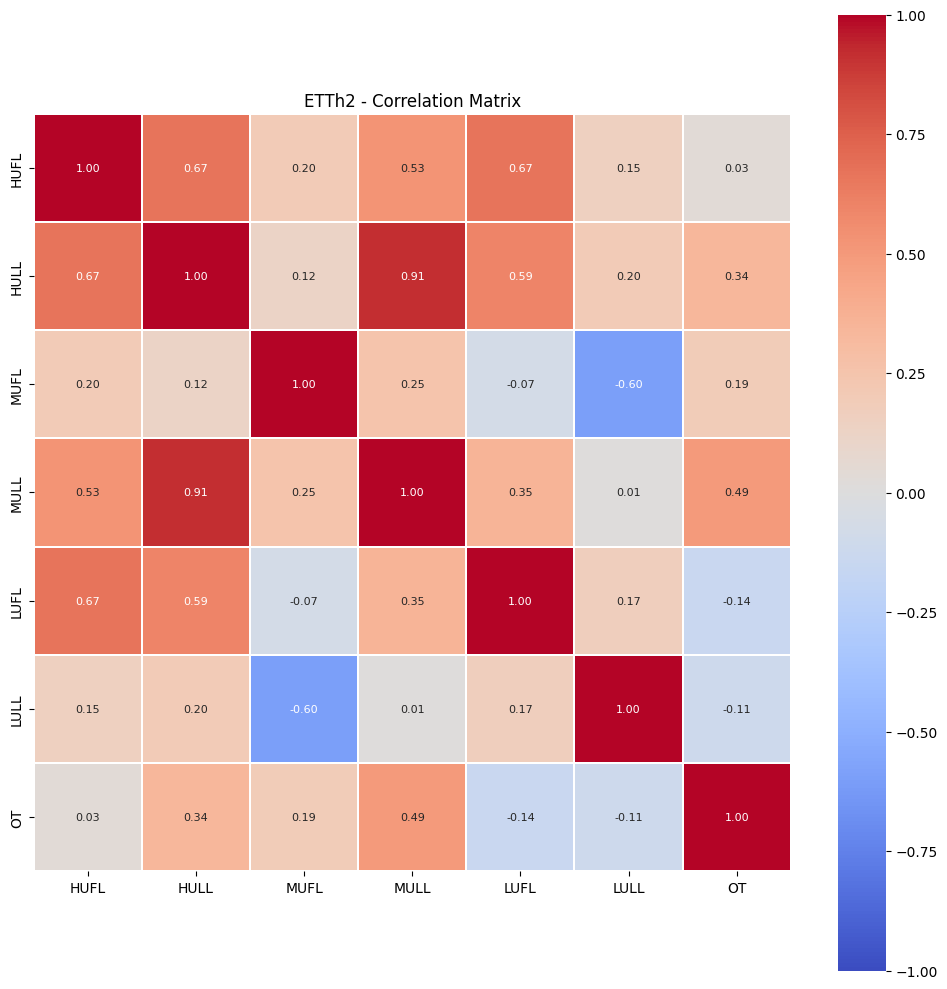

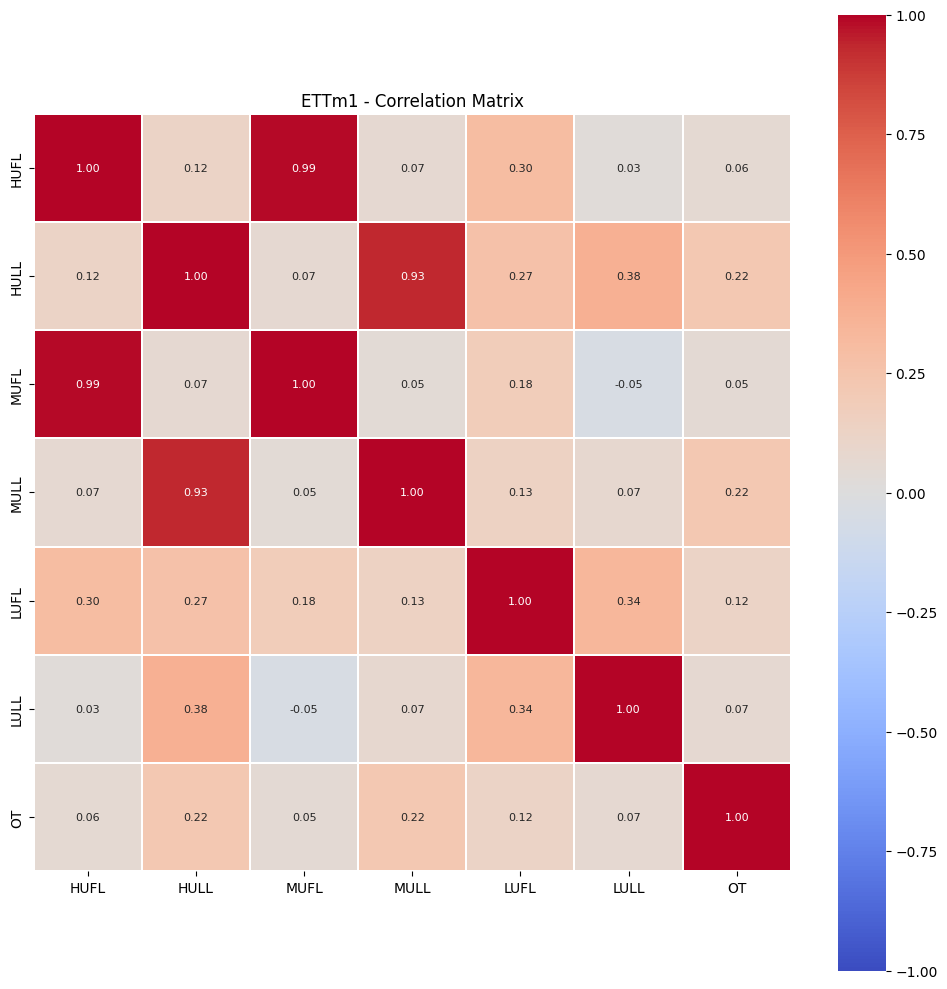

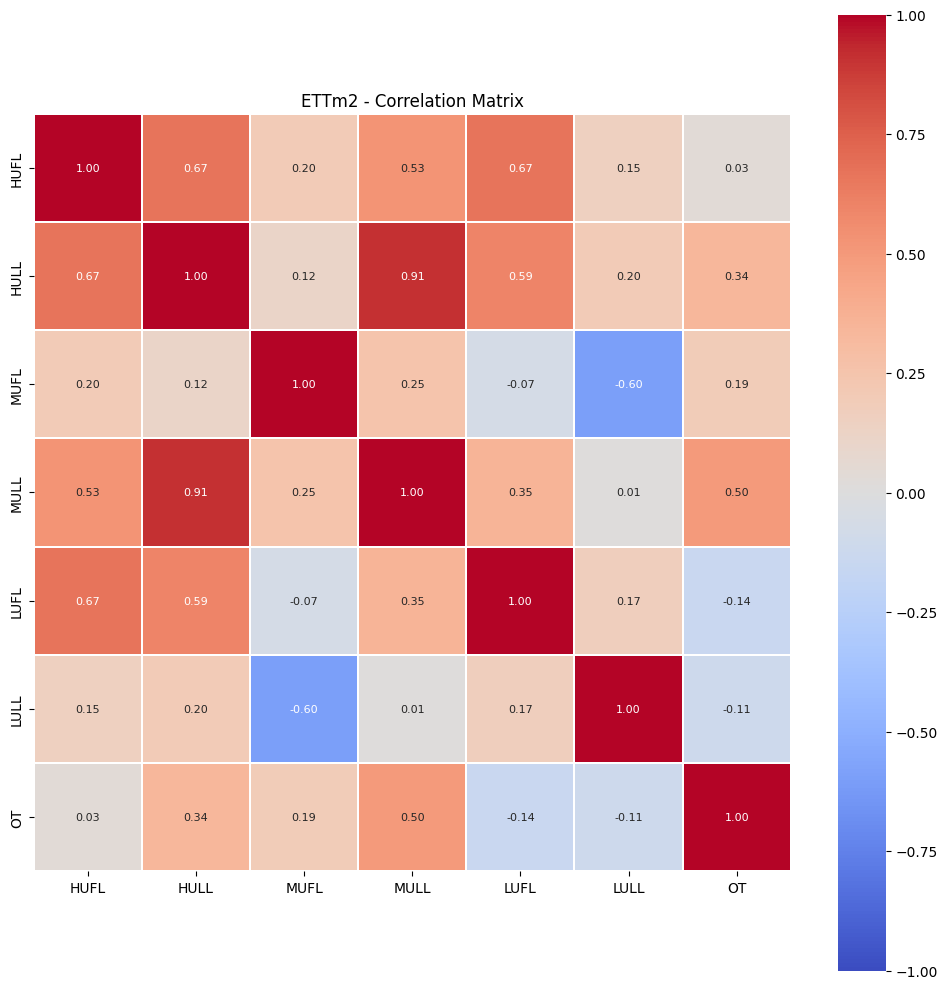

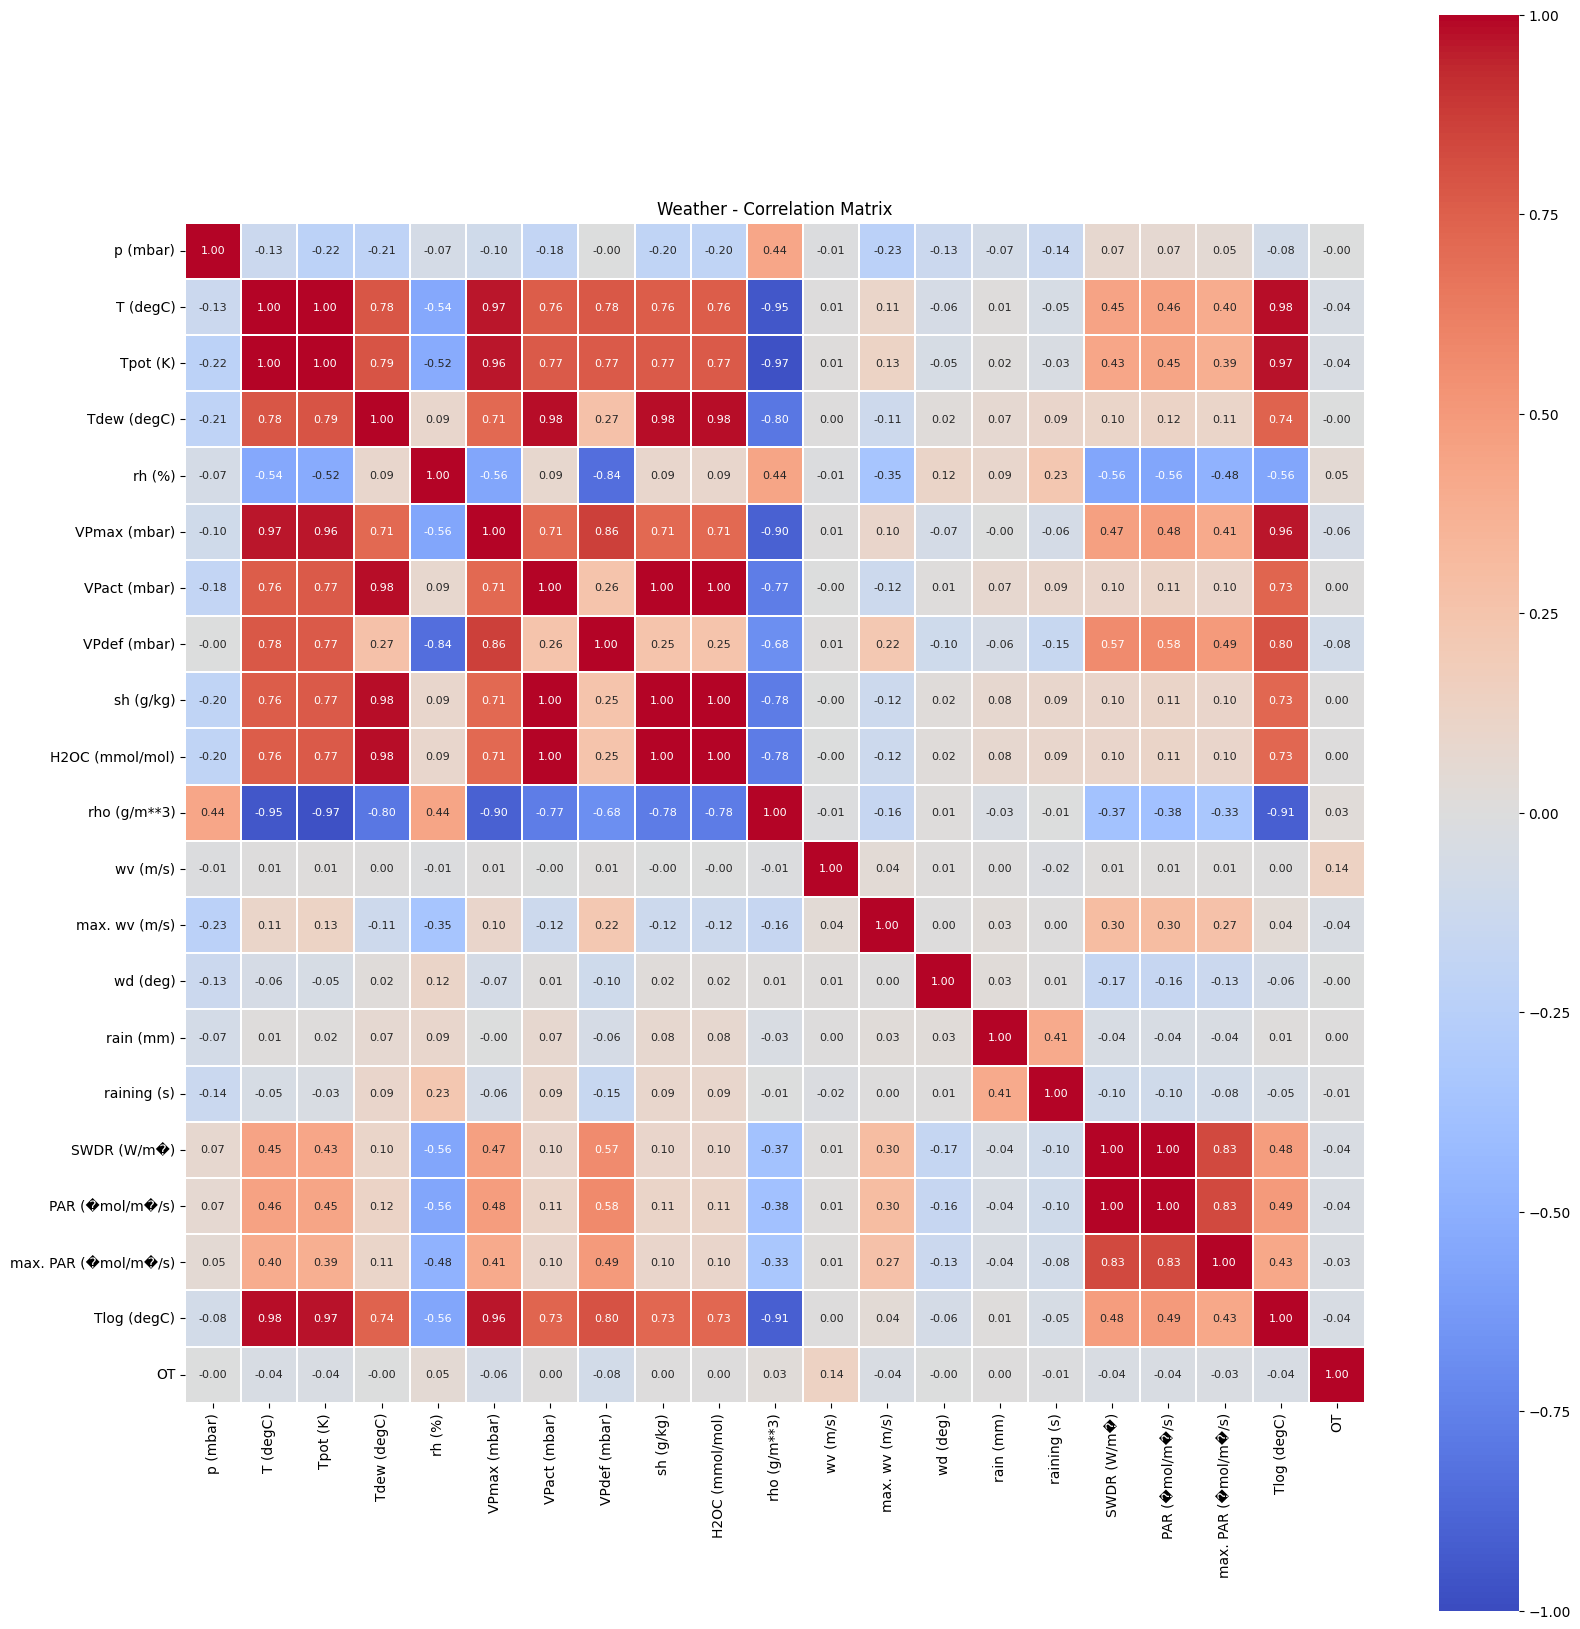

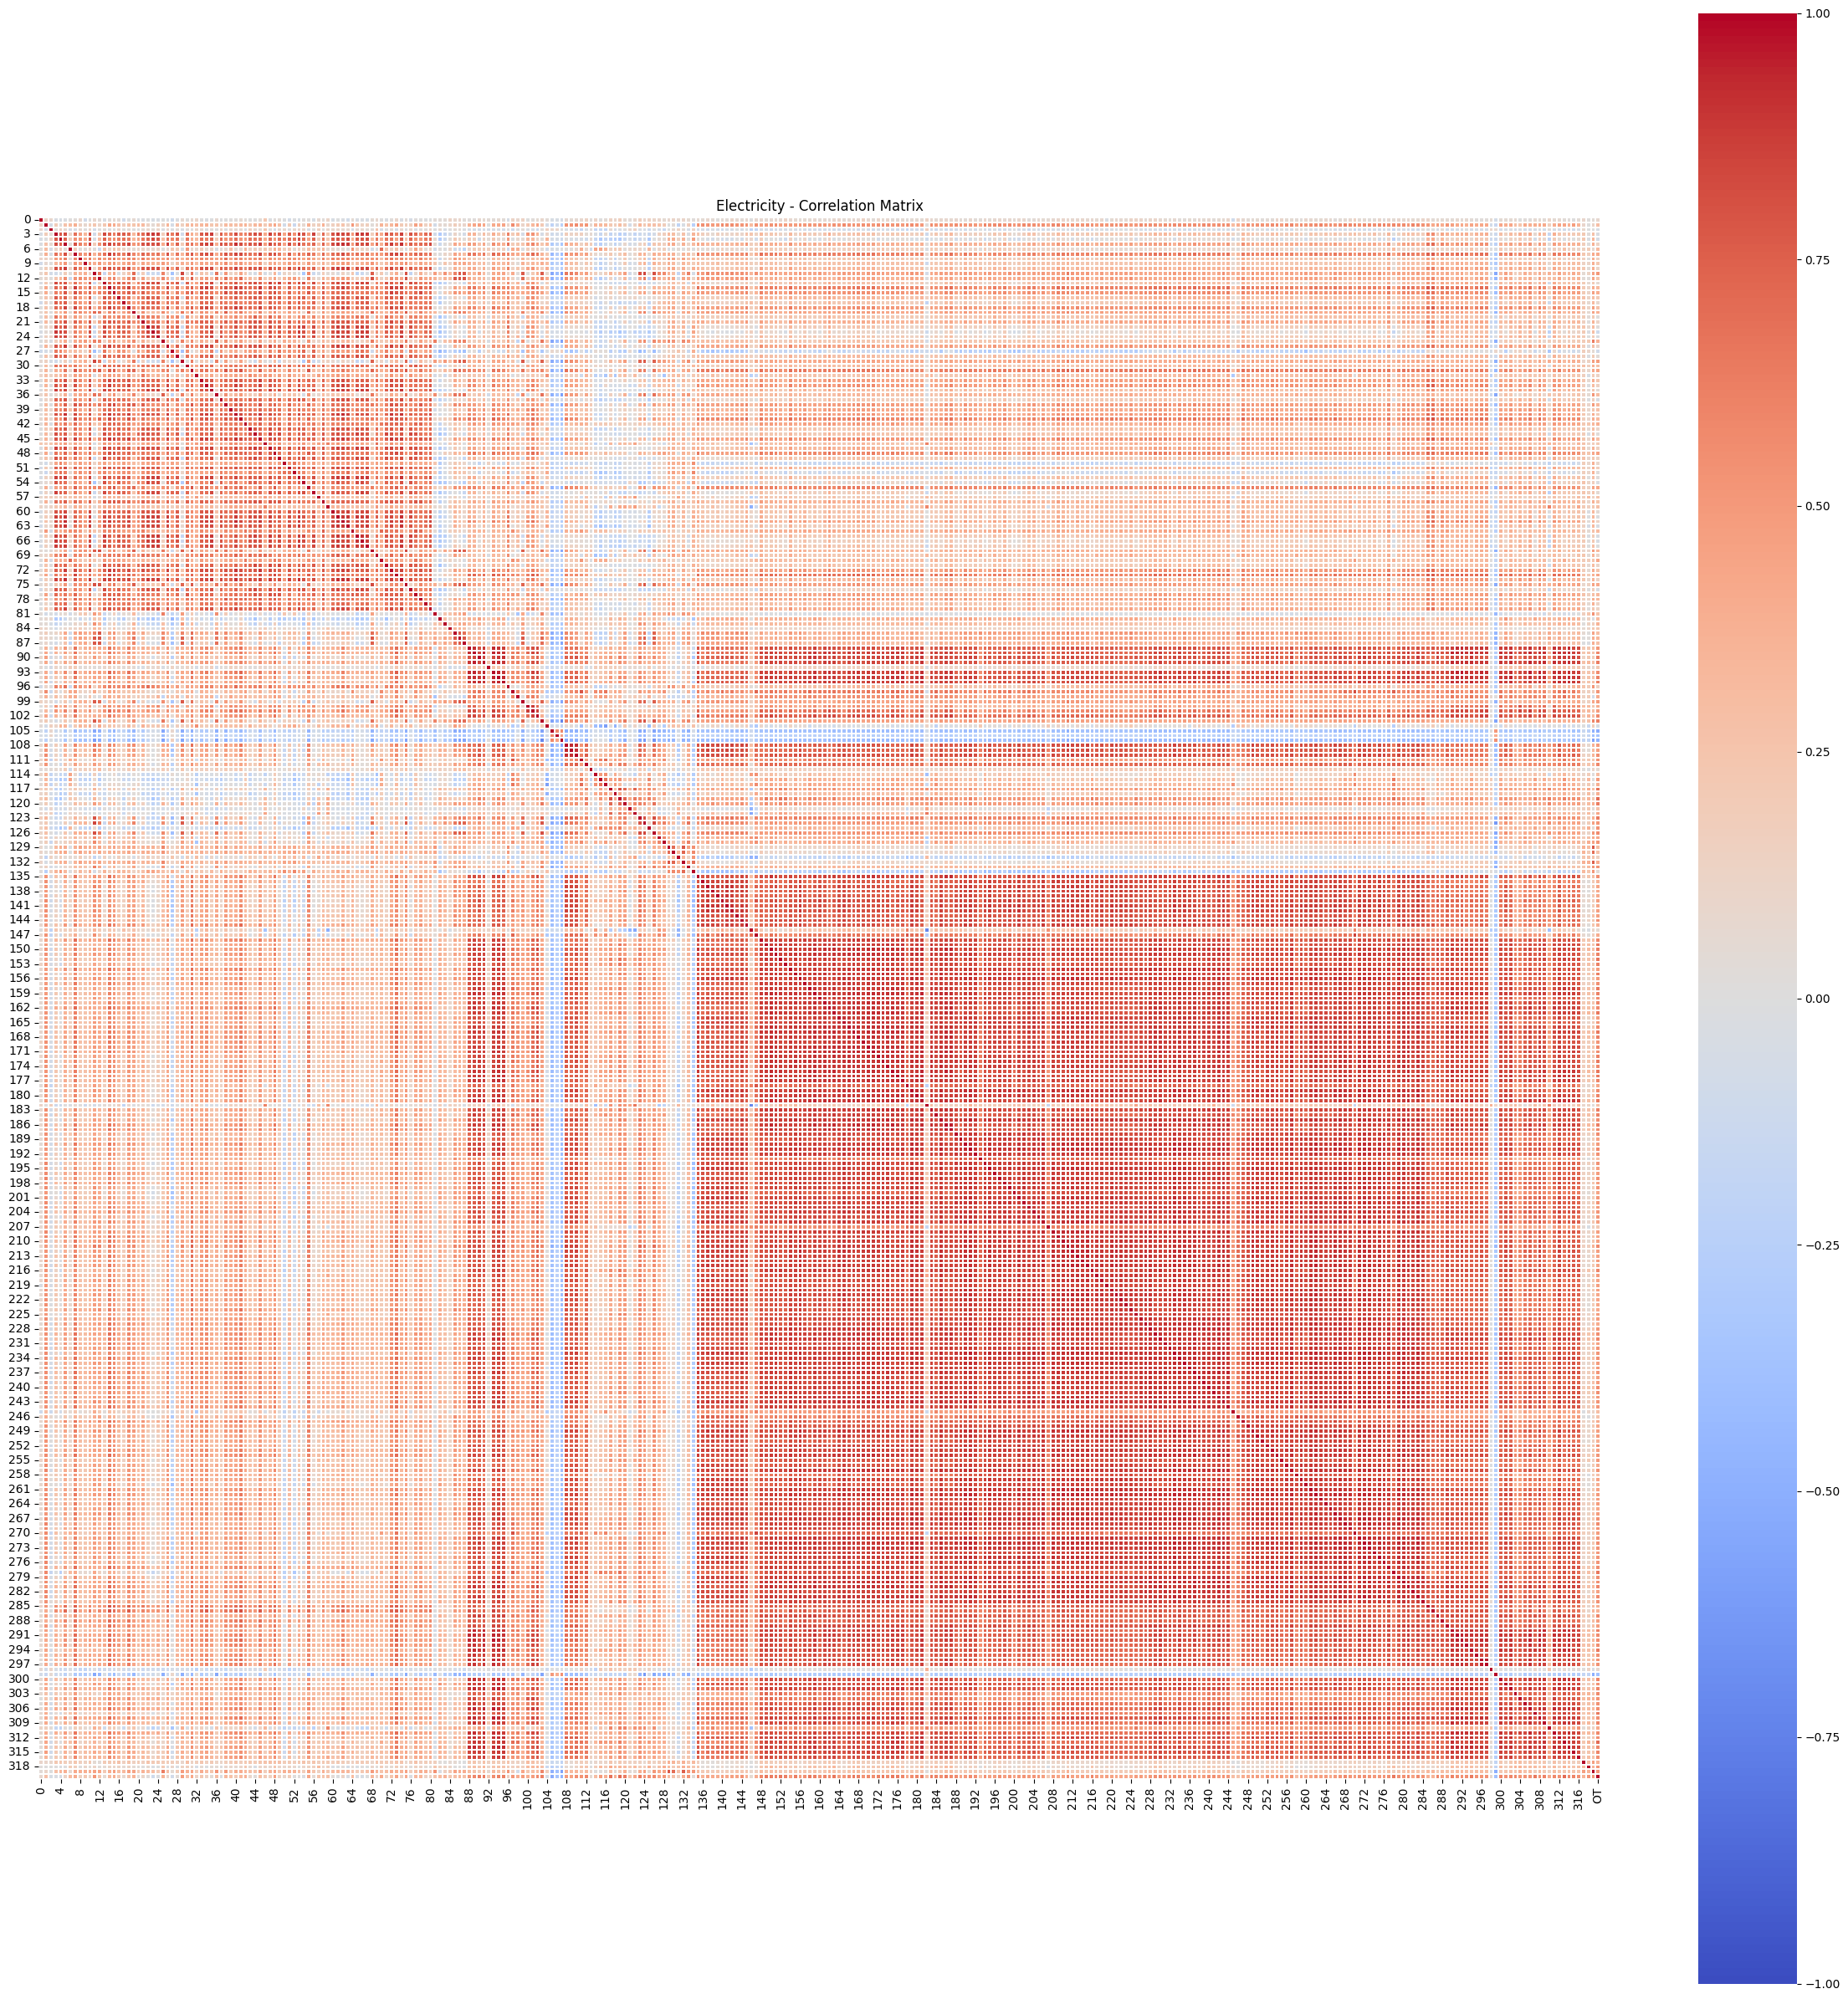

In [9]:
for name, path in DATASETS.items():
    if not path.exists():
        print(f"[NOT FOUND] {name}: {path}")
        continue

    df = pd.read_csv(path)
    numeric_df = df.select_dtypes(include="number")

    if numeric_df.shape[1] < 2:
        print(f"{name}: Không đủ biến số để tính tương quan.")
        continue

    corr = numeric_df.corr()

    # Điều chỉnh kích thước theo số lượng biến
    figure_size = max(10, min(24, len(corr.columns) * 0.8))
    plt.figure(figsize=(figure_size, figure_size))

    # Ẩn nhãn số ở Electricity để tránh biểu đồ quá rối
    show_numbers = name.lower() != "electricity"

    sns.heatmap(
        corr,
        annot=show_numbers,
        fmt=".2f",# làm tròn 
        cmap="coolwarm",
        center=0,
        vmin=-1,
        vmax=1,
        square=True,
        linewidths=0.3,
        annot_kws={"size": 8}
    )

    plt.title(f"{name} - Correlation Matrix")
    plt.tight_layout()
    plt.show()
    plt.close()

9. Box Plot phát hiện giá trị ngoại lai

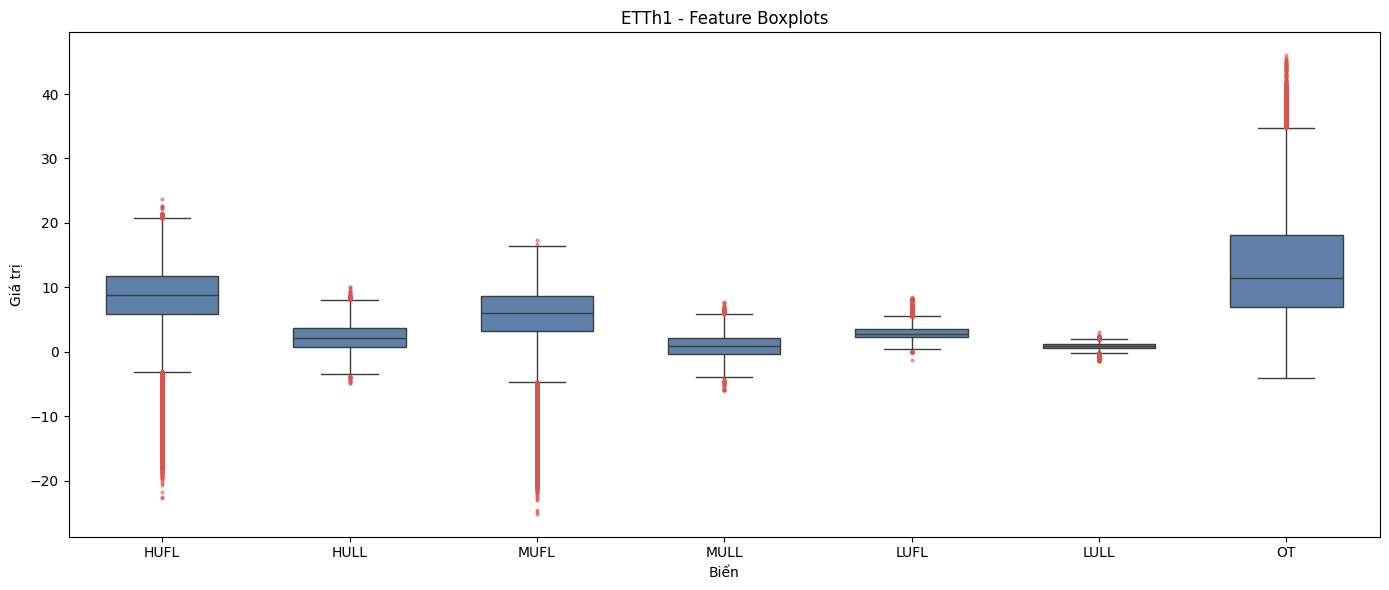

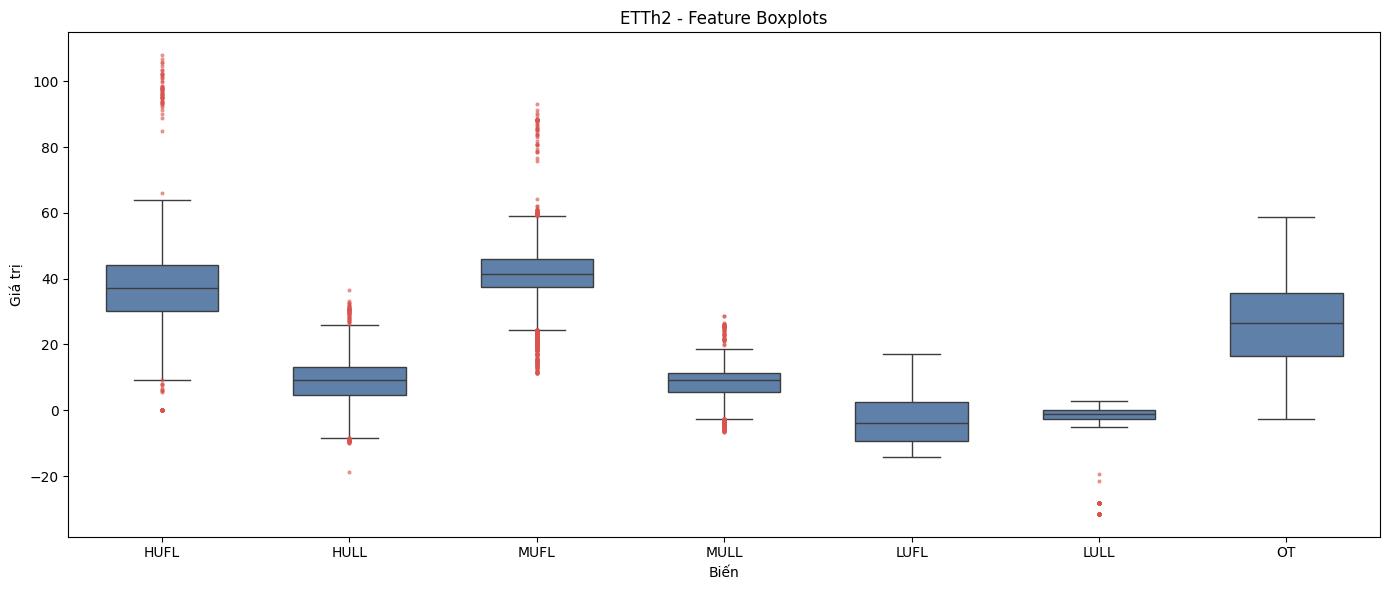

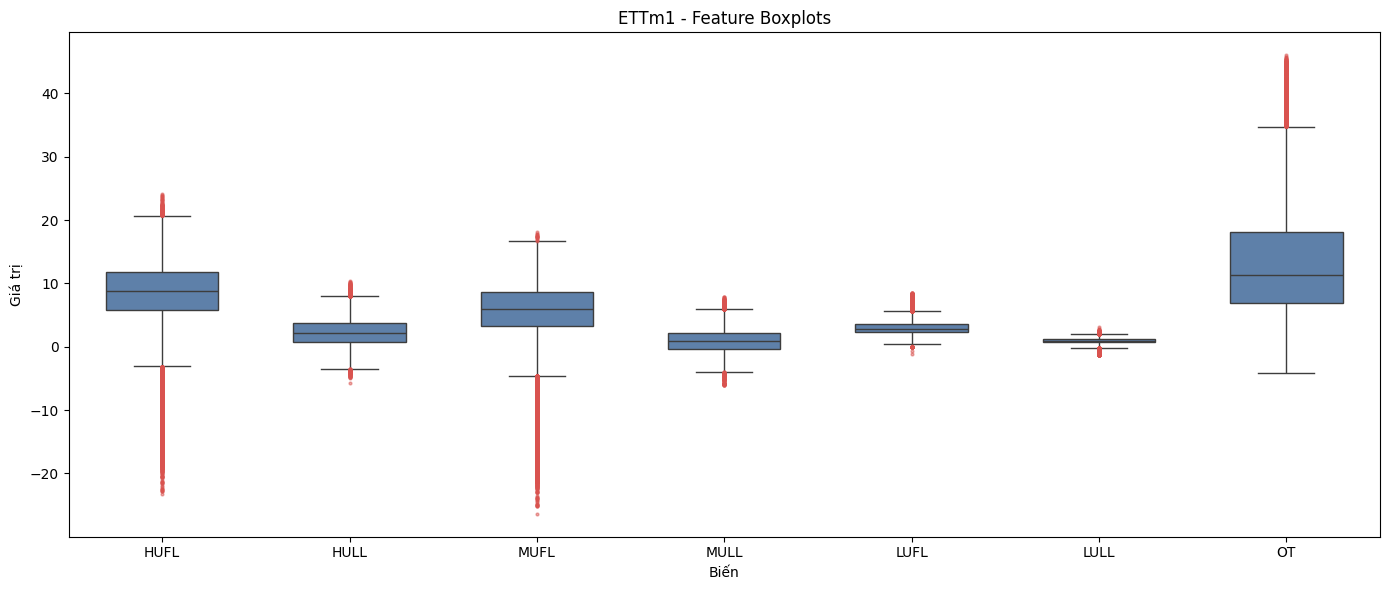

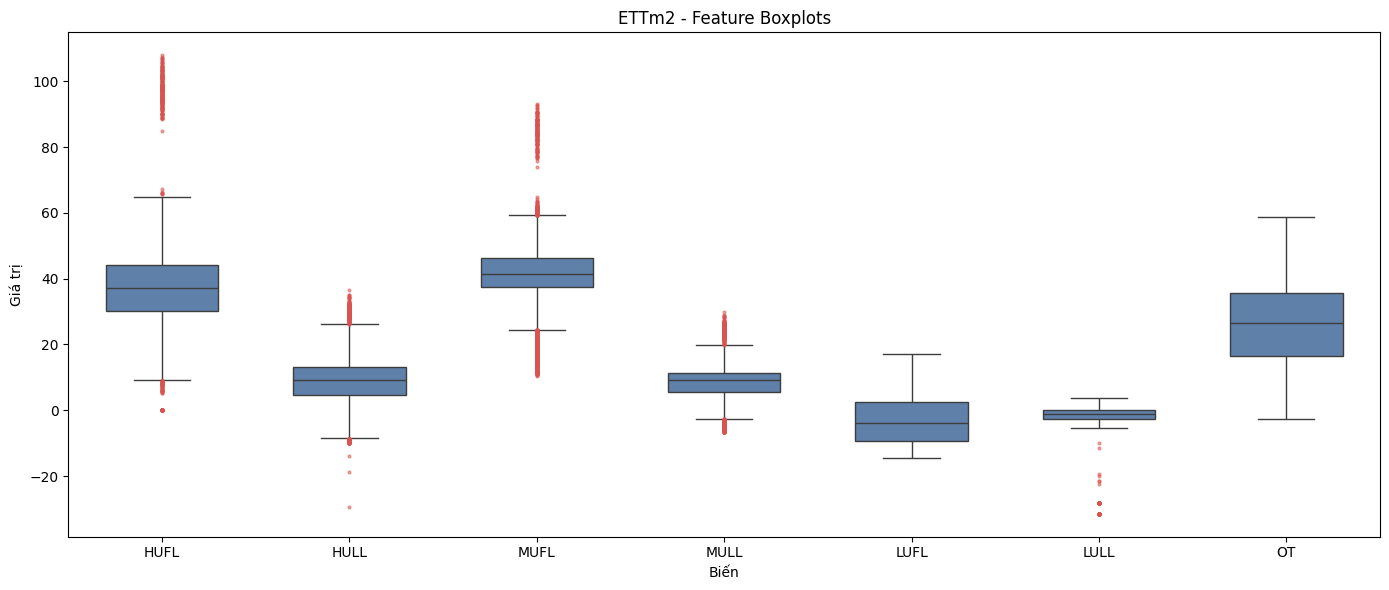

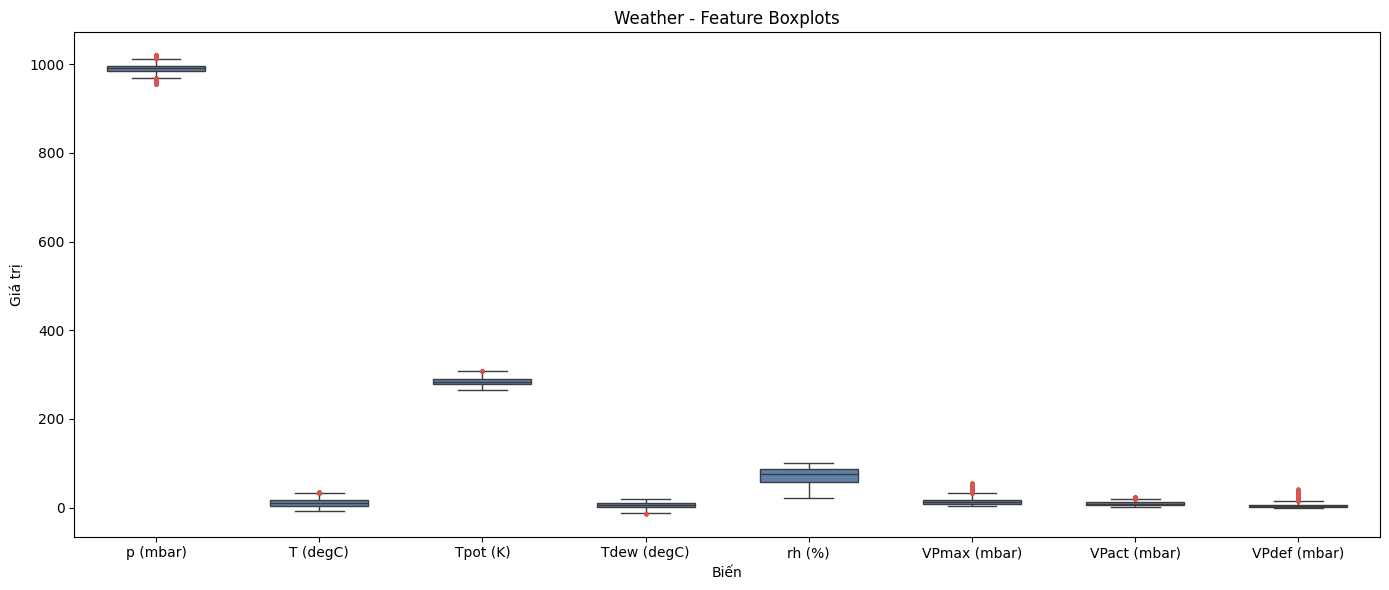

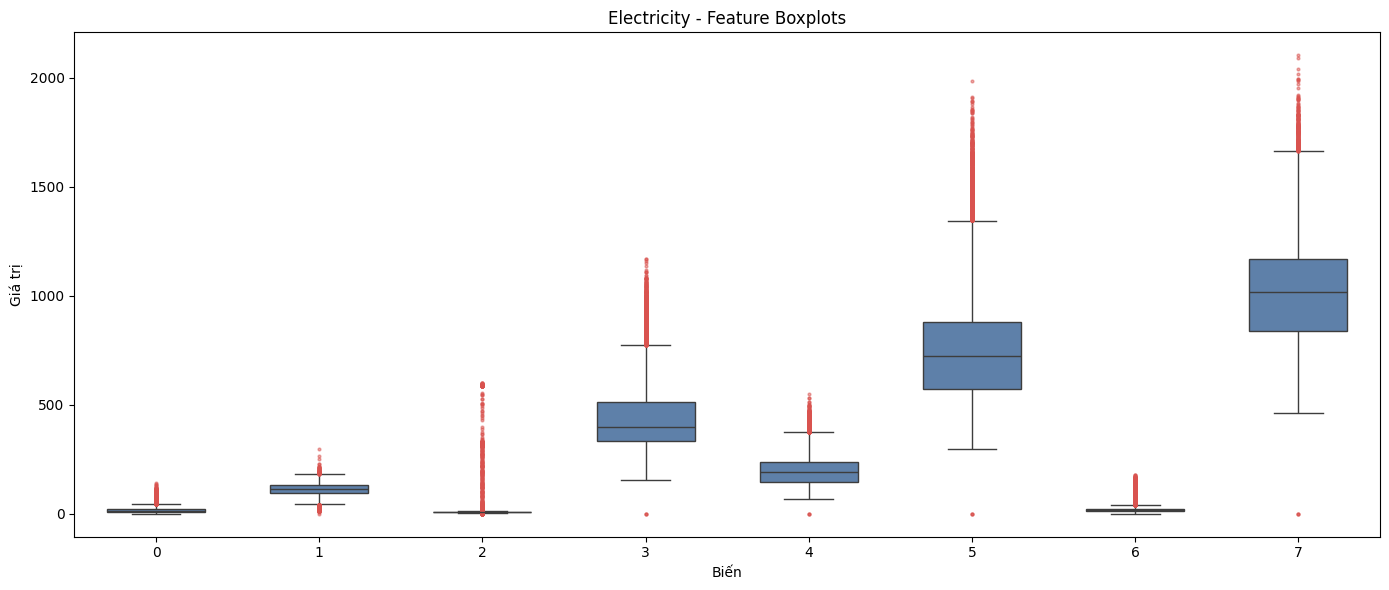

In [10]:
for name, path in DATASETS.items():
    if not path.exists():
        print(f"[NOT FOUND] {name}: {path}")
        continue

    df = pd.read_csv(path)
    numeric_cols = df.select_dtypes(include="number").columns.tolist()

    if not numeric_cols:
        print(f"{name}: Không có cột số.")
        continue

    # Chỉ chọn tối đa 8 biến để tránh biểu đồ quá dày
    selected_cols = numeric_cols[:8]

    plt.figure(figsize=(14, 6))

    sns.boxplot(
        data=df[selected_cols],
        color="#527FB5",
        width=0.6,
        flierprops={
            "marker": "o", # bd ngoại lai
            "markersize": 2,
            "markerfacecolor": "#D9534F",
            "markeredgecolor": "#D9534F",
            "alpha": 0.5
        }
    )

    plt.title(f"{name} - Feature Boxplots")
    plt.xlabel("Biến")
    plt.ylabel("Giá trị")
    plt.xticks(rotation=0)
    plt.tight_layout()
    plt.show()

In [11]:
# Tổng quan bộ dữ liệu và biến mục tiêu
from contextlib import redirect_stdout
from IPython.display import display, HTML

# Cho phép các dòng output dài xuống dòng trong Jupyter Notebook
display(HTML(
    "<style>.output pre { white-space: pre-wrap; }</style>"
))

output_file = Path("dataset_overview.txt")

with open(output_file, "w", encoding="utf-8") as f:
    with redirect_stdout(f):
        for name, path in DATASETS.items():
            if not path.exists():
                print(f"[KHÔNG TÌM THẤY] {name}: {path}")
                continue

            df = pd.read_csv(path)

            print("\n" + "=" * 60)
            print(f"Tên bộ dữ liệu: {name}")
            print(f"Kích thước dữ liệu: {df.shape}")
            print(f"Danh sách các cột: {list(df.columns)}")

            if "date" in df.columns:
                dates = pd.to_datetime(df["date"], errors="coerce")
                print(f"Thời điểm bắt đầu: {dates.min()}")
                print(f"Thời điểm kết thúc: {dates.max()}")

            if "OT" in df.columns:
                print("Cột OT: Có")
                print(
                    "Cần đối chiếu cấu hình thí nghiệm để xác nhận "
                    "OT có phải biến mục tiêu hay không."
                )
            else:
                print("Cột OT: Không có")
                print(
                    "Cần kiểm tra cấu hình và bộ đọc dữ liệu "
                    "để xác định biến mục tiêu."
                )

print(output_file.read_text(encoding="utf-8"))
print(f"\nĐã lưu kết quả tại: {output_file.resolve()}")



Tên bộ dữ liệu: ETTh1
Kích thước dữ liệu: (17420, 8)
Danh sách các cột: ['date', 'HUFL', 'HULL', 'MUFL', 'MULL', 'LUFL', 'LULL', 'OT']
Thời điểm bắt đầu: 2016-07-01 00:00:00
Thời điểm kết thúc: 2018-06-26 19:00:00
Cột OT: Có
Cần đối chiếu cấu hình thí nghiệm để xác nhận OT có phải biến mục tiêu hay không.

Tên bộ dữ liệu: ETTh2
Kích thước dữ liệu: (17420, 8)
Danh sách các cột: ['date', 'HUFL', 'HULL', 'MUFL', 'MULL', 'LUFL', 'LULL', 'OT']
Thời điểm bắt đầu: 2016-07-01 00:00:00
Thời điểm kết thúc: 2018-06-26 19:00:00
Cột OT: Có
Cần đối chiếu cấu hình thí nghiệm để xác nhận OT có phải biến mục tiêu hay không.

Tên bộ dữ liệu: ETTm1
Kích thước dữ liệu: (69680, 8)
Danh sách các cột: ['date', 'HUFL', 'HULL', 'MUFL', 'MULL', 'LUFL', 'LULL', 'OT']
Thời điểm bắt đầu: 2016-07-01 00:00:00
Thời điểm kết thúc: 2018-06-26 19:45:00
Cột OT: Có
Cần đối chiếu cấu hình thí nghiệm để xác nhận OT có phải biến mục tiêu hay không.

Tên bộ dữ liệu: ETTm2
Kích thước dữ liệu: (69680, 8)
Danh sách các cột: ['d

In [17]:
ALPHA = 0.05

for dataset_name, file_path in DATASETS.items():
    print("\n" + "=" * 65)
    print(f"ADF TEST - {dataset_name}")
    print("H0: Chuỗi có nghiệm đơn vị (unit root)")
    print("=" * 65)

    if not file_path.exists():
        print(f"Không tìm thấy file: {file_path}")
        continue

    df = pd.read_csv(file_path)

    # Loại bỏ cột thời gian
    time_cols = [
        col for col in df.columns
        if col.strip().lower() in {
            "date", "datetime", "timestamp", "time"
        }
    ]
    df = df.drop(columns=time_cols, errors="ignore")

    for col in df.columns:
        series = pd.to_numeric(df[col], errors="coerce").dropna()

        if len(series) < 10 or series.nunique() <= 1:
            print(f"{col}: Bỏ qua - dữ liệu không đủ hoặc không biến thiên")
            continue

        try:
            adf_stat, p_value, *_ = adfuller(series)

            if p_value < ALPHA:
                conclusion = "Bác bỏ H0 - Có bằng chứng chuỗi dừng"
            else:
                conclusion = "Chưa đủ bằng chứng bác bỏ H0"

            print(
                f"{col}: ADF = {adf_stat:.4f} | "
                f"p-value = {p_value:.6f} | {conclusion}"
            )

        except Exception as e:
            print(f"{col}: Không thể kiểm định ({e})")


ADF TEST - ETTh1
H0: Chuỗi có nghiệm đơn vị (unit root)
HUFL: ADF = -8.5505 | p-value = 0.000000 | Bác bỏ H0 - Có bằng chứng chuỗi dừng
HULL: ADF = -5.1691 | p-value = 0.000010 | Bác bỏ H0 - Có bằng chứng chuỗi dừng
MUFL: ADF = -8.6212 | p-value = 0.000000 | Bác bỏ H0 - Có bằng chứng chuỗi dừng
MULL: ADF = -4.9641 | p-value = 0.000026 | Bác bỏ H0 - Có bằng chứng chuỗi dừng
LUFL: ADF = -5.7969 | p-value = 0.000000 | Bác bỏ H0 - Có bằng chứng chuỗi dừng
LULL: ADF = -4.7727 | p-value = 0.000061 | Bác bỏ H0 - Có bằng chứng chuỗi dừng
OT: ADF = -3.4880 | p-value = 0.008302 | Bác bỏ H0 - Có bằng chứng chuỗi dừng

ADF TEST - ETTh2
H0: Chuỗi có nghiệm đơn vị (unit root)
HUFL: ADF = -6.5264 | p-value = 0.000000 | Bác bỏ H0 - Có bằng chứng chuỗi dừng
HULL: ADF = -4.5542 | p-value = 0.000157 | Bác bỏ H0 - Có bằng chứng chuỗi dừng
MUFL: ADF = -4.0446 | p-value = 0.001194 | Bác bỏ H0 - Có bằng chứng chuỗi dừng
MULL: ADF = -4.4530 | p-value = 0.000239 | Bác bỏ H0 - Có bằng chứng chuỗi dừng
LUFL: AD